# Credit Card Users Churn Prediction

## Problem Statement

### Business Context

The Thera bank recently saw a steep decline in the number of users of their credit card, credit cards are a good source of income for banks because of different kinds of fees charged by the banks like annual fees, balance transfer fees, and cash advance fees, late payment fees, foreign transaction fees, and others. Some fees are charged to every user irrespective of usage, while others are charged under specified circumstances.

Customers’ leaving credit cards services would lead bank to loss, so the bank wants to analyze the data of customers and identify the customers who will leave their credit card services and reason for same – so that bank could improve upon those areas

You as a Data scientist at Thera bank need to come up with a classification model that will help the bank improve its services so that customers do not renounce their credit cards

### Data Description

* CLIENTNUM: Client number. Unique identifier for the customer holding the account
* Attrition_Flag: Internal event (customer activity) variable - if the account is closed then "Attrited Customer" else "Existing Customer"
* Customer_Age: Age in Years
* Gender: Gender of the account holder
* Dependent_count: Number of dependents
* Education_Level: Educational Qualification of the account holder - Graduate, High School, Unknown, Uneducated, College(refers to college student), Post-Graduate, Doctorate
* Marital_Status: Marital Status of the account holder
* Income_Category: Annual Income Category of the account holder
* Card_Category: Type of Card
* Months_on_book: Period of relationship with the bank (in months)
* Total_Relationship_Count: Total no. of products held by the customer
* Months_Inactive_12_mon: No. of months inactive in the last 12 months
* Contacts_Count_12_mon: No. of Contacts in the last 12 months
* Credit_Limit: Credit Limit on the Credit Card
* Total_Revolving_Bal: Total Revolving Balance on the Credit Card
* Avg_Open_To_Buy: Open to Buy Credit Line (Average of last 12 months)
* Total_Amt_Chng_Q4_Q1: Change in Transaction Amount (Q4 over Q1)
* Total_Trans_Amt: Total Transaction Amount (Last 12 months)
* Total_Trans_Ct: Total Transaction Count (Last 12 months)
* Total_Ct_Chng_Q4_Q1: Change in Transaction Count (Q4 over Q1)
* Avg_Utilization_Ratio: Average Card Utilization Ratio

#### What Is a Revolving Balance?

- If we don't pay the balance of the revolving credit account in full every month, the unpaid portion carries over to the next month. That's called a revolving balance


##### What is the Average Open to buy?

- 'Open to Buy' means the amount left on your credit card to use. Now, this column represents the average of this value for the last 12 months.

##### What is the Average utilization Ratio?

- The Avg_Utilization_Ratio represents how much of the available credit the customer spent. This is useful for calculating credit scores.


##### Relation b/w Avg_Open_To_Buy, Credit_Limit and Avg_Utilization_Ratio:

- ( Avg_Open_To_Buy / Credit_Limit ) + Avg_Utilization_Ratio = 1

### **Please read the instructions carefully before starting the project.**
This is a commented Jupyter IPython Notebook file in which all the instructions and tasks to be performed are mentioned.
* Blanks '_______' are provided in the notebook that
needs to be filled with an appropriate code to get the correct result. With every '_______' blank, there is a comment that briefly describes what needs to be filled in the blank space.
* Identify the task to be performed correctly, and only then proceed to write the required code.
* Fill the code wherever asked by the commented lines like "# write your code here" or "# complete the code". Running incomplete code may throw error.
* Please run the codes in a sequential manner from the beginning to avoid any unnecessary errors.
* Add the results/observations (wherever mentioned) derived from the analysis in the presentation and submit the same.


## Importing necessary libraries

In [ ]:
# Installing the libraries with the specified version.
# uncomment and run the following line if Google Colab is being used
!pip install scikit-learn==1.2.2 seaborn==0.13.1 matplotlib==3.7.1 numpy==1.25.2 pandas==1.5.3 imbalanced-learn==0.10.1 xgboost==2.0.3 -q --user

In [ ]:
# Installing the libraries with the specified version.
# uncomment and run the following lines if Jupyter Notebook is being used
# !pip install scikit-learn==1.2.2 seaborn==0.13.1 matplotlib==3.7.1 numpy==1.25.2 pandas==1.5.3 imblearn==0.12.0 xgboost==2.0.3 -q --user
# !pip install --upgrade -q threadpoolctl

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again*.

In [ ]:
# To help with reading and manipulating data
import pandas as pd
import numpy as np

# To help with data visualization
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

# To be used for missing value imputation
from sklearn.impute import SimpleImputer
from sklearn import metrics

# To help with model building
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier,
)
from xgboost import XGBClassifier

# To get different metric scores, and split data
from sklearn import metrics
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

# To be used for data scaling and one hot encoding
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder

# To be used for tuning the model
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# To define maximum number of columns to be displayed in a dataframe
pd.set_option("display.max_columns", None)

# To supress scientific notations for a dataframe
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To supress warnings
import warnings

warnings.filterwarnings("ignore")


## Loading the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:
bc = pd.read_csv('/content/drive/MyDrive/Great Learning/Project 3: Advanced Machine Learning/BankChurners.csv')

In [ ]:
bc.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.000,777,11914.000,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.000,864,7392.000,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.000,0,3418.000,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,3313.000,2517,796.000,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.000,0,4716.000,2.175,816,28,2.500,0.000


## Data Overview

- Observations
- Sanity checks

###Sanity Checks

In [ ]:
#Making a copy of the bc data frame to ensure clean and untampered data
df = bc.copy()

In [ ]:
df.shape

(10127, 21)

From the shape function we can confirm that there are 21 different variables in the data. We also see that there are 10,127 rows of data in this data set we cannot confirm that the 10,127 rows are unique/ seperate customers yet.

In [ ]:
#View first 5 rows of Data Set
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.000,777,11914.000,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.000,864,7392.000,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.000,0,3418.000,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,3313.000,2517,796.000,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.000,0,4716.000,2.175,816,28,2.500,0.000


In [ ]:
#View last 5 rows of Data Set
df.tail()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,3,2,3,4003.000,1851,2152.000,0.703,15476,117,0.857,0.462
10123,710638233,Attrited Customer,41,M,2,NaN,Divorced,$40K - $60K,Blue,25,4,2,3,4277.000,2186,2091.000,0.804,8764,69,0.683,0.511
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,5,3,4,5409.000,0,5409.000,0.819,10291,60,0.818,0.000
10125,717406983,Attrited Customer,30,M,2,Graduate,NaN,$40K - $60K,Blue,36,4,3,3,5281.000,0,5281.000,0.535,8395,62,0.722,0.000
10126,714337233,Attrited Customer,43,F,2,Graduate,Married,Less than $40K,Silver,25,6,2,4,10388.000,1961,8427.000,0.703,10294,61,0.649,0.189


In [ ]:
#Check data types in bc data set
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CLIENTNUM                 10127 non-null  int64  
 1   Attrition_Flag            10127 non-null  object 
 2   Customer_Age              10127 non-null  int64  
 3   Gender                    10127 non-null  object 
 4   Dependent_count           10127 non-null  int64  
 5   Education_Level           8608 non-null   object 
 6   Marital_Status            9378 non-null   object 
 7   Income_Category           10127 non-null  object 
 8   Card_Category             10127 non-null  object 
 9   Months_on_book            10127 non-null  int64  
 10  Total_Relationship_Count  10127 non-null  int64  
 11  Months_Inactive_12_mon    10127 non-null  int64  
 12  Contacts_Count_12_mon     10127 non-null  int64  
 13  Credit_Limit              10127 non-null  float64
 14  Total_

From the .info section we can see that there are 6 object data type variables, attrition_flag, Gender, Education_Level, Maritial_status, Income category, card_category. The remainder of the variables are float or integer data types. Of the different variables education level and marital status are the only variables with potential missing values.

In [ ]:
df.isnull().sum()

,0
CLIENTNUM,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,1519
Marital_Status,749
Income_Category,0
Card_Category,0
Months_on_book,0


The above function confirms the findings from the .info function. We see that Education Level has 1519 missing values and 749 missing values in marital status.

In [ ]:
# let's check for missing values in the data
round(df.isnull().sum() / df.isnull().count() * 100, 2)

,0
CLIENTNUM,0.000
Attrition_Flag,0.000
Customer_Age,0.000
Gender,0.000
Dependent_count,0.000
Education_Level,15.000
Marital_Status,7.400
Income_Category,0.000
Card_Category,0.000
Months_on_book,0.000


When we convert the above values into percentages we can see that Education_Level and Marital_Status have 15% and 7.4% of their values missing respectively. Due to the low percentage and these variables being categorical we can use the mode of these variables to treat these missing values. These values will be treated

In [ ]:
# let's check for duplicate rows in the data
df.duplicated().sum()

0

We can see that there are no dublicate rows or customers in this data set.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CLIENTNUM,10127.000,739177606.334,36903783.450,708082083.000,713036770.500,717926358.000,773143533.000,828343083.000
Customer_Age,10127.000,46.326,8.017,26.000,41.000,46.000,52.000,73.000
Dependent_count,10127.000,2.346,1.299,0.000,1.000,2.000,3.000,5.000
Months_on_book,10127.000,35.928,7.986,13.000,31.000,36.000,40.000,56.000
Total_Relationship_Count,10127.000,3.813,1.554,1.000,3.000,4.000,5.000,6.000
Months_Inactive_12_mon,10127.000,2.341,1.011,0.000,2.000,2.000,3.000,6.000
Contacts_Count_12_mon,10127.000,2.455,1.106,0.000,2.000,2.000,3.000,6.000
Credit_Limit,10127.000,8631.954,9088.777,1438.300,2555.000,4549.000,11067.500,34516.000
Total_Revolving_Bal,10127.000,1162.814,814.987,0.000,359.000,1276.000,1784.000,2517.000
Avg_Open_To_Buy,10127.000,7469.140,9090.685,3.000,1324.500,3474.000,9859.000,34516.000


Now we use the .describe() function to see the statistical break down of the numerical variables. We use the .T adaptation to make the data more legible and swap axis.

As we can see here the average age of a customer is 46 years and the average credit limit is 8,631 dollars.

With the CLIENTNUM variable being an unique identifier we can drop that column from the data.

Dependant count might also be an interesting factor to look as it is only integers and see how big of a role does it play in customers dropping the card.

In [ ]:
# list of all categorical variables
cat_col = df.columns

# printing the percentage of occurrences of each unique value in each categorical column
for column in cat_col:
    if  df[column].dtype == 'object':
      print(df[column].value_counts(normalize=True)*100)
      print("-" * 50)

Attrition_Flag
Existing Customer   83.934
Attrited Customer   16.066
Name: proportion, dtype: float64
--------------------------------------------------
Gender
F   52.908
M   47.092
Name: proportion, dtype: float64
--------------------------------------------------
Education_Level
Graduate        36.338
High School     23.385
Uneducated      17.275
College         11.768
Post-Graduate    5.994
Doctorate        5.239
Name: proportion, dtype: float64
--------------------------------------------------
Marital_Status
Married    49.979
Single     42.045
Divorced    7.976
Name: proportion, dtype: float64
--------------------------------------------------
Income_Category
Less than $40K   35.163
$40K - $60K      17.676
$80K - $120K     15.157
$60K - $80K      13.844
abc              10.981
$120K +           7.179
Name: proportion, dtype: float64
--------------------------------------------------
Card_Category
Blue       93.177
Silver      5.480
Gold        1.145
Platinum    0.197
Name: proport

We see that there is only one uniquie value that is only one unique value in the Income Category, abc, that we need to revisit to clean up.

In [ ]:
# list of all neumerical variables and their unique values
cat_col = df.columns

# printing the percentage of occurrences of each unique value in each categorical column
for column in cat_col:
    if  df[column].dtype != 'object':
      print(df[column].value_counts(normalize=True)*100)
      print("-" * 50)

CLIENTNUM
768805383   0.010
711784908   0.010
720133908   0.010
803197833   0.010
812222208   0.010
             ... 
796903083   0.010
716014983   0.010
712521783   0.010
780045708   0.010
714337233   0.010
Name: proportion, Length: 10127, dtype: float64
--------------------------------------------------
Customer_Age
44   4.937
49   4.888
46   4.839
45   4.799
47   4.730
43   4.671
48   4.661
50   4.463
42   4.207
51   3.930
53   3.821
41   3.742
52   3.713
40   3.565
39   3.288
54   3.031
38   2.992
55   2.755
56   2.587
37   2.567
57   2.202
36   2.182
35   1.817
59   1.550
58   1.550
34   1.442
33   1.254
60   1.254
32   1.047
65   0.997
61   0.918
62   0.918
31   0.899
26   0.770
30   0.691
63   0.642
29   0.553
64   0.425
27   0.316
28   0.286
67   0.039
66   0.020
68   0.020
70   0.010
73   0.010
Name: proportion, dtype: float64
--------------------------------------------------
Dependent_count
3   26.977
2   26.217
1   18.150
4   15.543
0    8.927
5    4.187
Name: proportion, d

In [ ]:
df = df.iloc[: , 1:]
df.head()


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.000,777,11914.000,1.335,1144,42,1.625,0.061
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.000,864,7392.000,1.541,1291,33,3.714,0.105
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.000,0,3418.000,2.594,1887,20,2.333,0.000
3,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,3313.000,2517,796.000,1.405,1171,20,2.333,0.760
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.000,0,4716.000,2.175,816,28,2.500,0.000


Droping the first column the client number and print it to check

In [ ]:
# Create a copy of data to perform detailed EDA
data = df.copy()

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. How is the total transaction amount distributed?
2. What is the distribution of the level of education of customers?
3. What is the distribution of the level of income of customers?
4. How does the change in transaction amount between Q4 and Q1 (`total_ct_change_Q4_Q1`) vary by the customer's account status (`Attrition_Flag`)?
5. How does the number of months a customer was inactive in the last 12 months (`Months_Inactive_12_mon`) vary by the customer's account status (`Attrition_Flag`)?
6. What are the attributes that have a strong correlation with each other?



#### The below functions need to be defined to carry out the Exploratory Data Analysis.

In [ ]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [ ]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

In [ ]:
# function to plot stacked bar chart

def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 1, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

In [ ]:
### Function to plot distributions

def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

In [ ]:
### Function to plot distributions with out box plots

def distribution_plot(data, predictor, target):

    fig, axs = plt.subplots(1, 2, figsize=(12, 5))

    target_uniq = data[target].unique()

    axs[0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0],
        color="teal",
    )

    axs[1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[1],
        color="orange",
    )

    plt.tight_layout()
    plt.show()

#####How is the total transaction amount distributed?

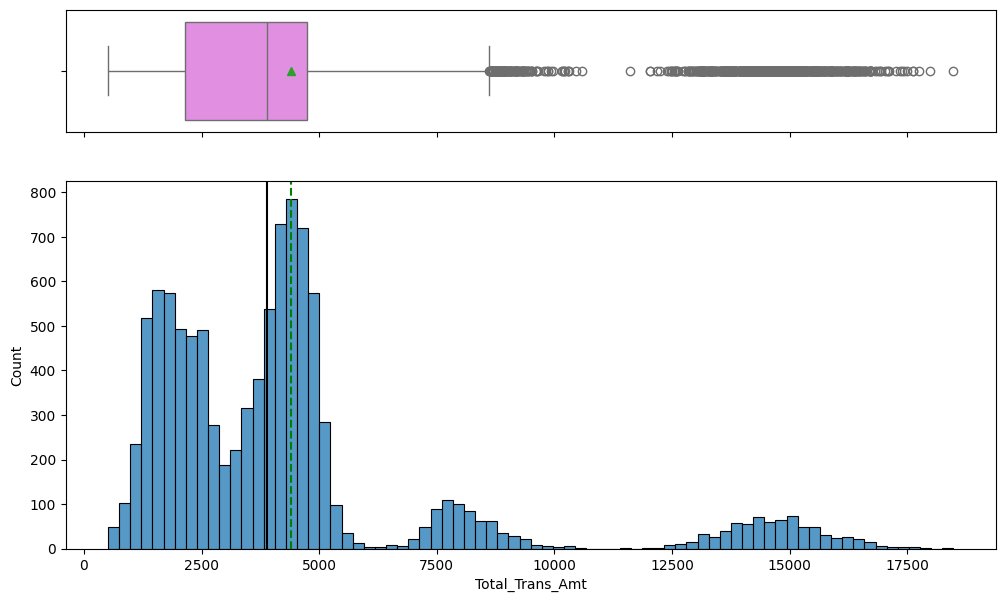

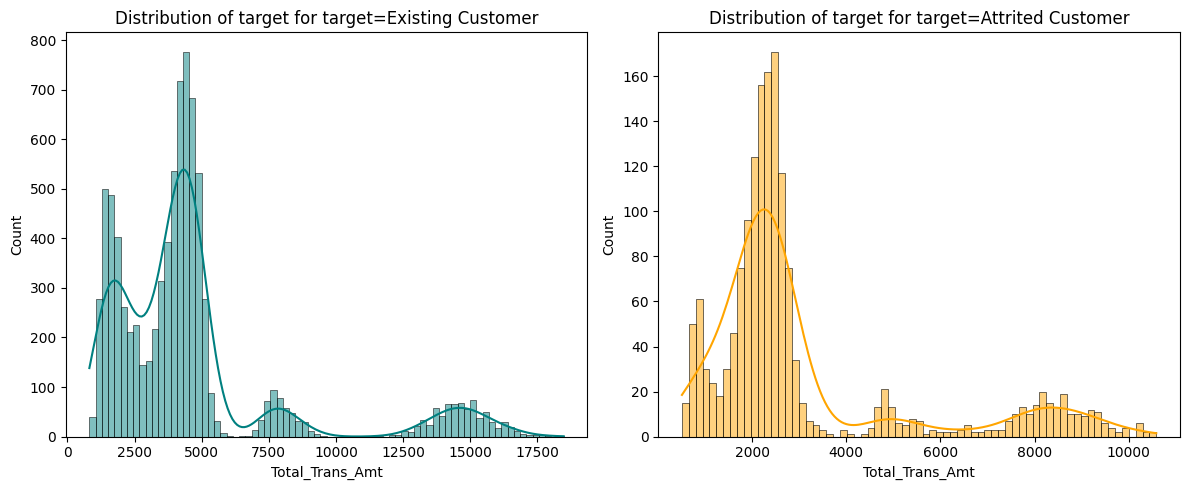

In [ ]:
# How is the total transaction amount distributed?

histogram_boxplot(data, "Total_Trans_Amt")
distribution_plot(data, "Total_Trans_Amt", "Attrition_Flag")



We see that the total transaction ammount has a bimodal distribution that is right right skewed. We can also see that the average for the total transaction ammount in the past 12 months is $4404. We also seen that the median is $3899. We see that the IQR is $2585.50.

Via the box plot we have no lower outliers but we have upper outlier at $8619.25. This is important as these outliers might be indicative of people that are more likely to keep their account open as they use the cards more.

Furthermore with distribution_plot we can see that the distribution is mimiced across existing and attrited customers. We can see this via the distribution plots in the in the function.

Need to bin due to skew

#####What is the distribution of the level of education of customers?

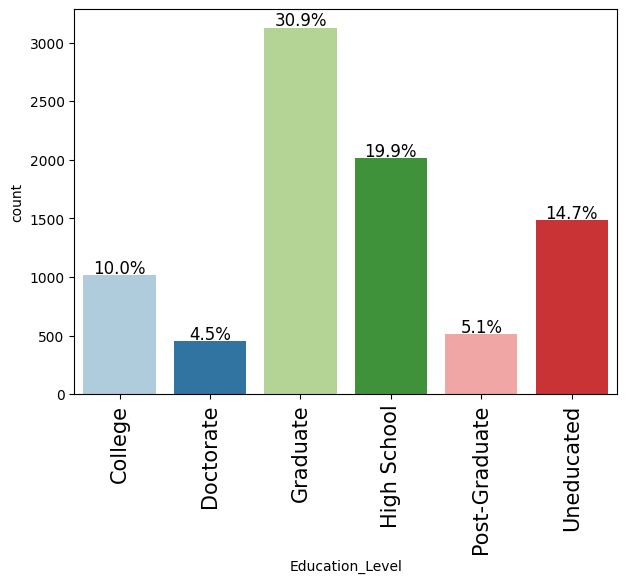

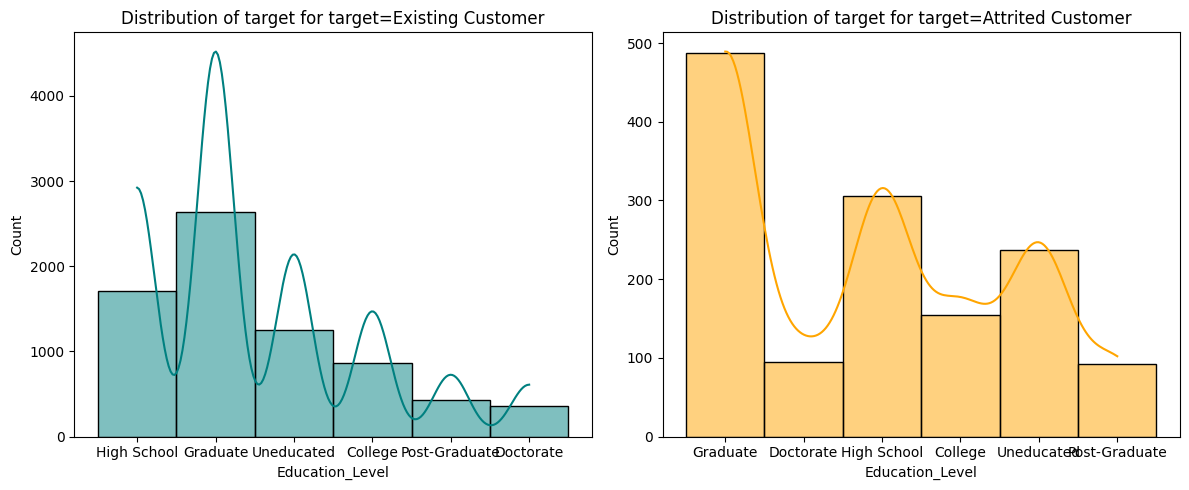

Attrition_Flag   Attrited Customer  Existing Customer   All
Education_Level                                            
All                           1371               7237  8608
Graduate                       487               2641  3128
High School                    306               1707  2013
Uneducated                     237               1250  1487
College                        154                859  1013
Doctorate                       95                356   451
Post-Graduate                   92                424   516
------------------------------------------------------------------------------------------------------------------------


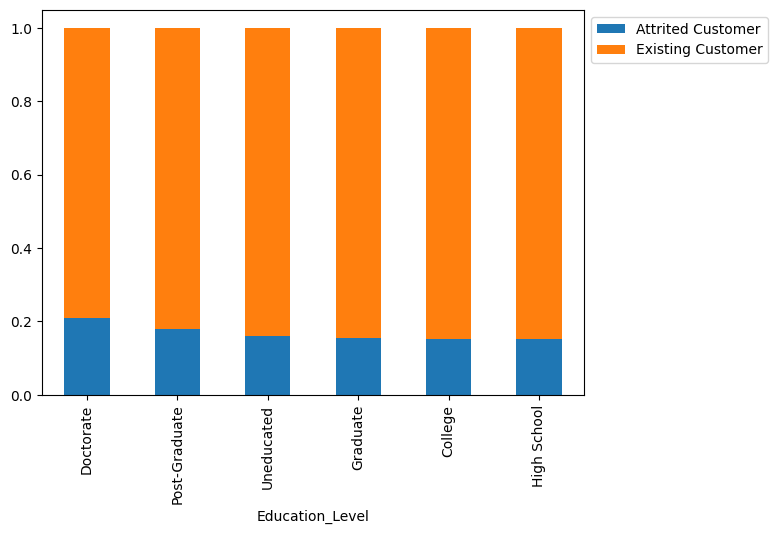

In [ ]:
labeled_barplot(data, "Education_Level", perc=True)
distribution_plot(data, "Education_Level", "Attrition_Flag")
stacked_barplot(data, "Education_Level", "Attrition_Flag")

We can see that across all the banks customers that 30% of the customers have a graduate degree or level of education. The next most common level of education is High School at 19.9% and uneducated at 14.4%.

Further we can see that there is a higher probablity of attrited customers coming from a High School or uneducated background than existing customers. This is a important point to keep in mind.

*Note only using existing functions for the sake of time and efficiency.

The Stacked Barplot shows the percentage of each education level's split between existing and attrited customers.

#####What is the distribution of the level of income of customers?

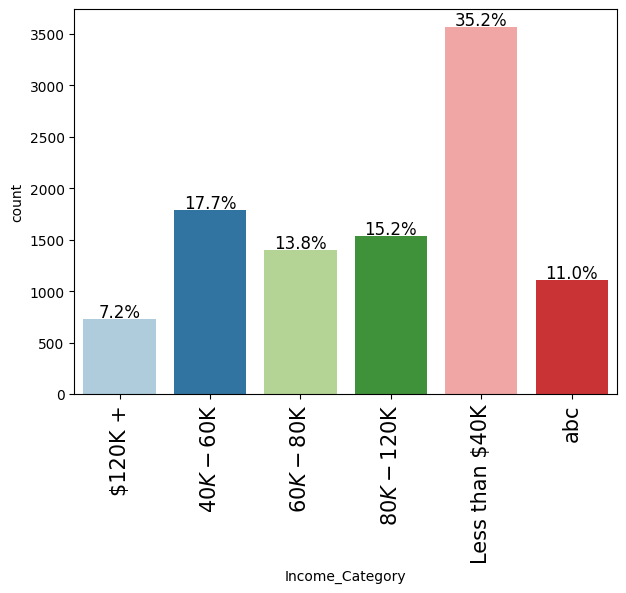

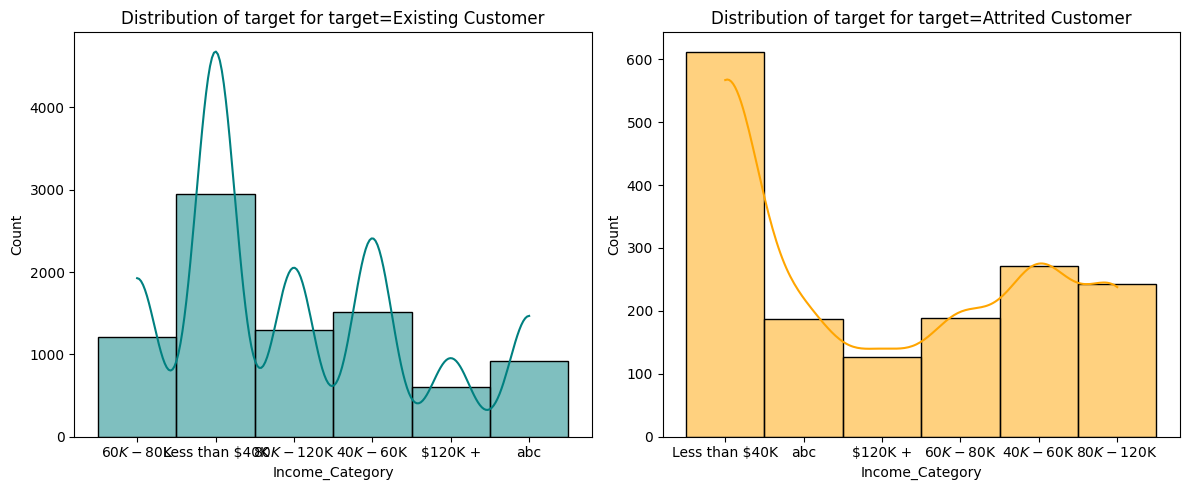

Attrition_Flag   Attrited Customer  Existing Customer    All
Income_Category                                             
All                           1627               8500  10127
Less than $40K                 612               2949   3561
$40K - $60K                    271               1519   1790
$80K - $120K                   242               1293   1535
$60K - $80K                    189               1213   1402
abc                            187                925   1112
$120K +                        126                601    727
------------------------------------------------------------------------------------------------------------------------


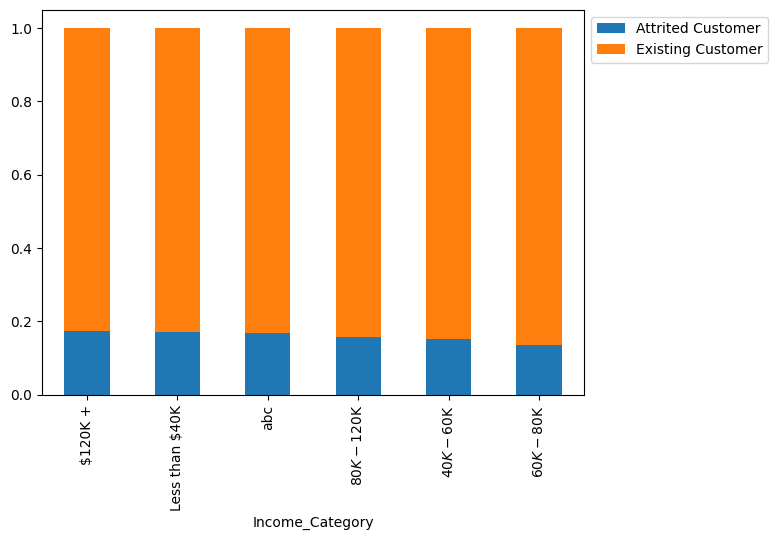

In [ ]:
labeled_barplot(data, "Income_Category", perc=True)
distribution_plot(data, "Income_Category", "Attrition_Flag")
stacked_barplot(data, "Income_Category", "Attrition_Flag")

From the above labeled bar plot we can see that most of this bank's customers make less than 40k per year. we also see that 11% of the the customers chose not to respond to the question.

Also in the Distribution and kernel density graphs above we see that for existing and attrited customers that the less than 40K per year demographic has the highest count and probability with the 40k-60k group having the next highest demographic. Which reflects the previously stated conclusion from the labeled bar plot.

The Stacked Barplot shows the percentage of each income categories split between existing and attrited customers.

#####How does the change in transaction amount between Q4 and Q1 (total_ct_change_Q4_Q1) vary by the customer's account status (Attrition_Flag)?

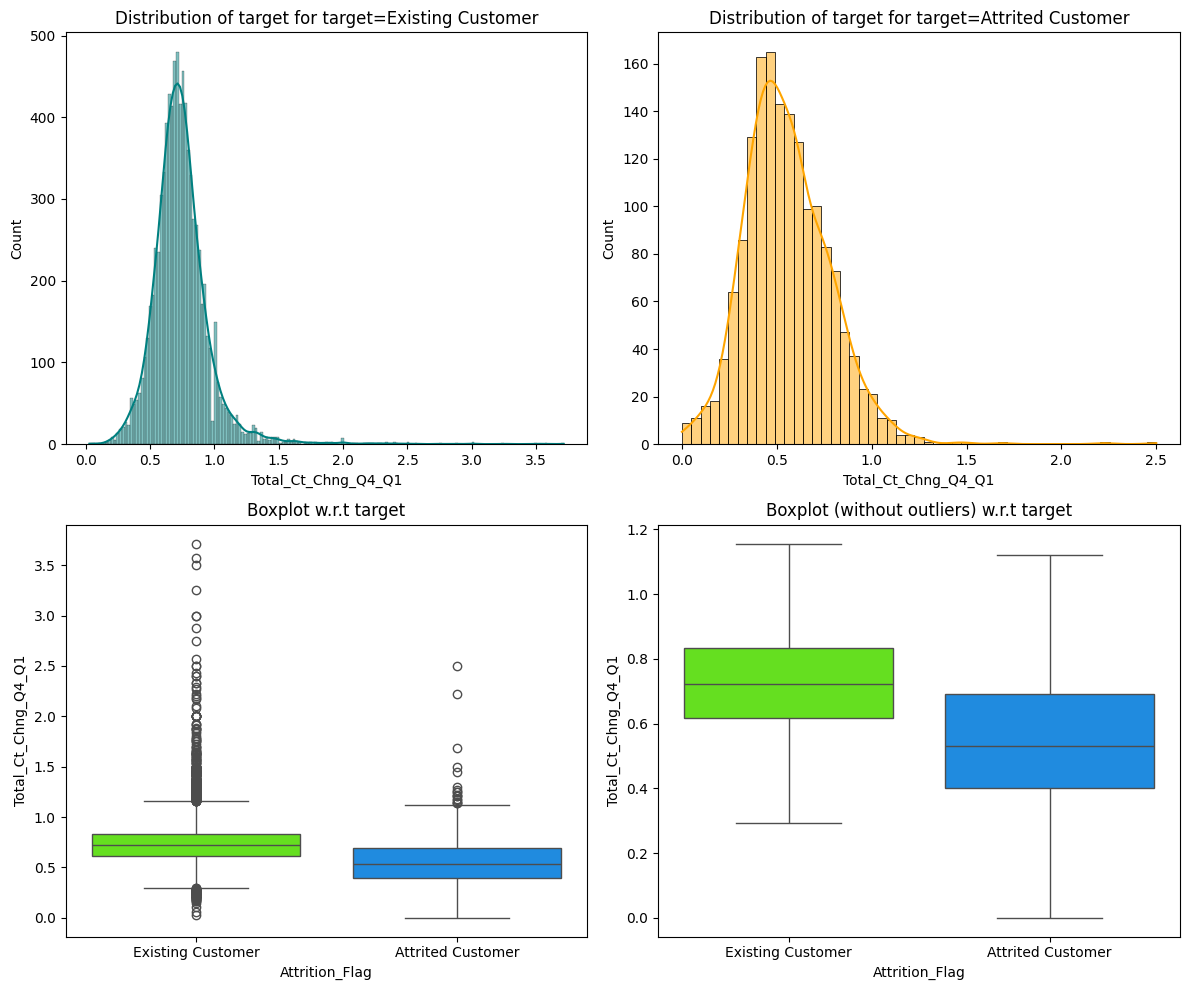

In [ ]:
distribution_plot_wrt_target(data, "Total_Ct_Chng_Q4_Q1", "Attrition_Flag")


From the above distribution graphs we see that both existing customers and attrited customers have unimodal distributions for the total transaction count change from Q4 to Q1. We can also see that it is right skewed which is reflected in the box plots. Via the box plots we can see that the median count change is higher for existing customers than attrited customers. This means that existing customers use their cards more than attrited customers during Q4. But with both medians being under 1 we can conclude that more transactions occur during Q1 than Q4.

#####How does the number of months a customer was inactive in the last 12 months (Months_Inactive_12_mon) vary by the customer's account status (Attrition_Flag)?

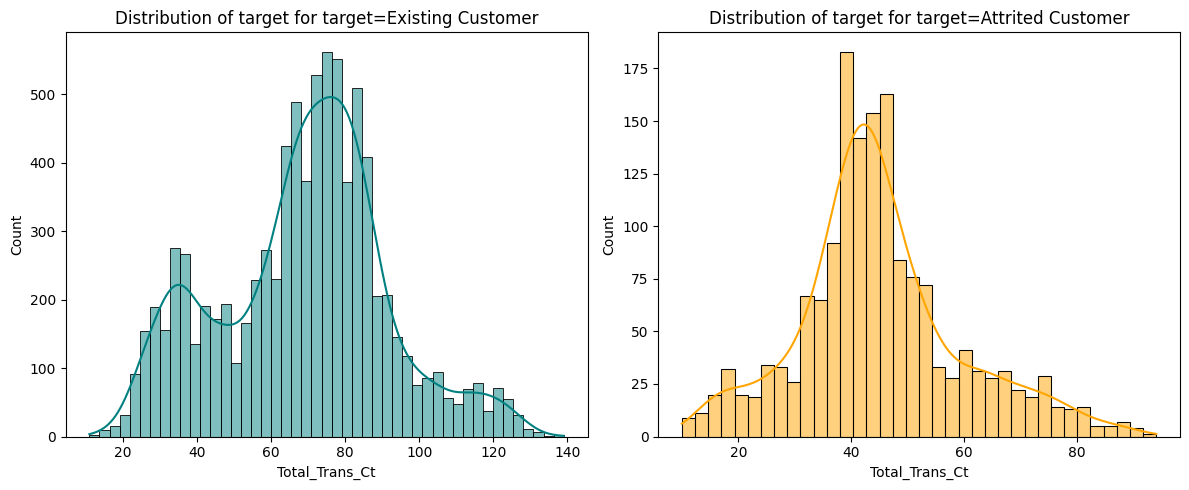

In [358]:
distribution_plot(data, "Total_Trans_Ct", "Attrition_Flag")

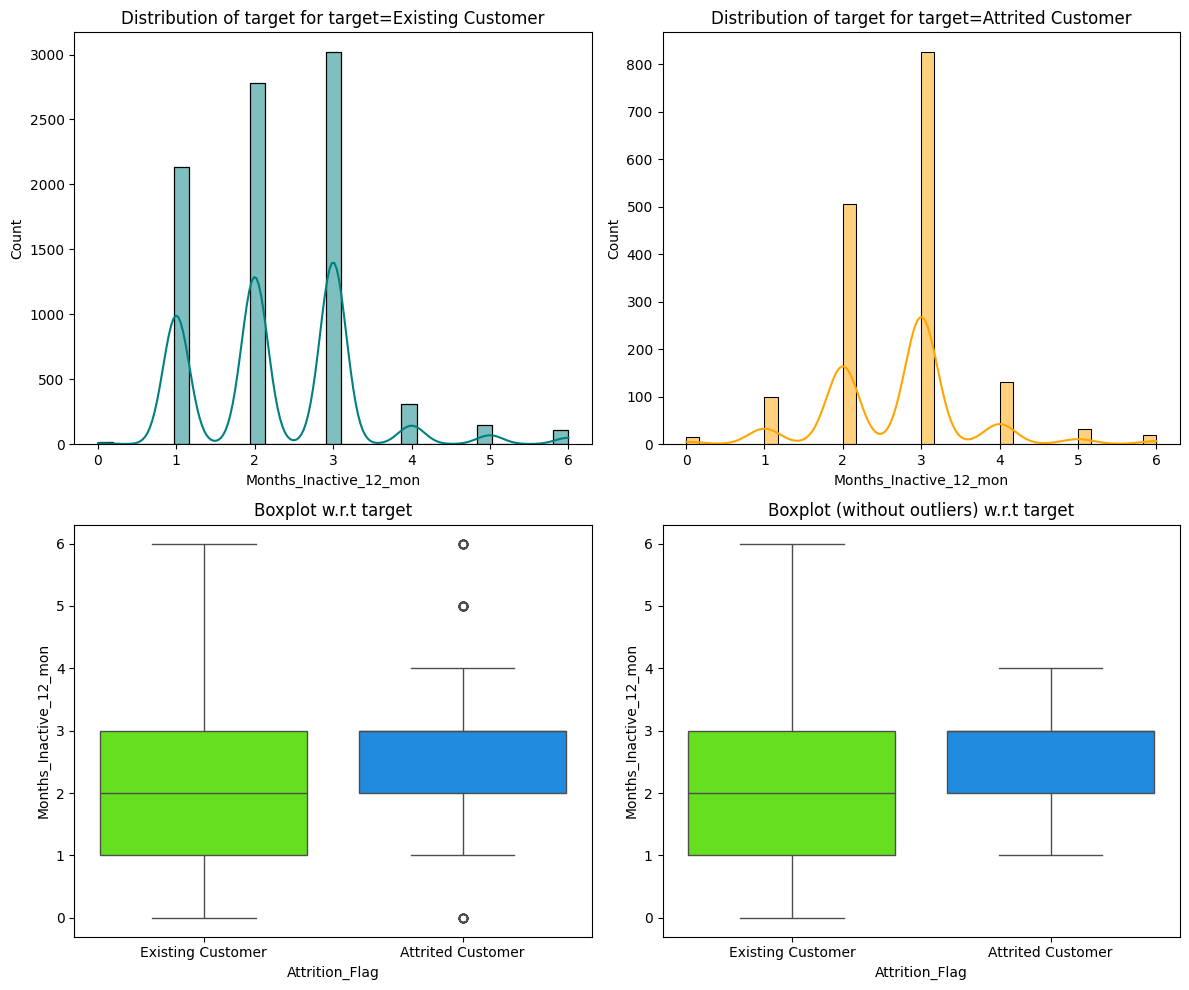

Attrition_Flag          Attrited Customer  Existing Customer    All
Months_Inactive_12_mon                                             
All                                  1627               8500  10127
3                                     826               3020   3846
2                                     505               2777   3282
4                                     130                305    435
1                                     100               2133   2233
5                                      32                146    178
6                                      19                105    124
0                                      15                 14     29
------------------------------------------------------------------------------------------------------------------------


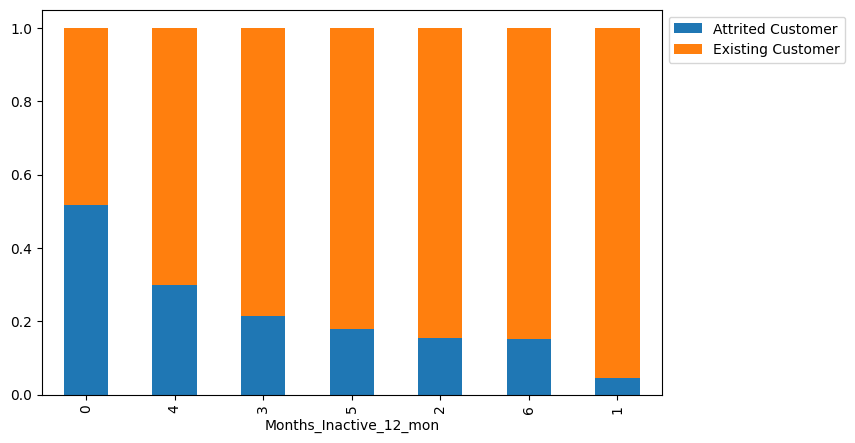

In [ ]:
distribution_plot_wrt_target(data, "Months_Inactive_12_mon", "Attrition_Flag")
stacked_barplot(data, "Months_Inactive_12_mon", "Attrition_Flag")

As seen in the distribution graphs' we observe that for exisiting customers they have a higher count of people that are inactive between 1-3 months. For Attritioned customers there is a higher count of 2-4 month inactivness. We can confirm the outliers using the box and whisker plot. For Attrited customers we see that the median and the thried quartile are 3 months so we can infer that once customers hit the 3 month mark of inactivity they are more likely to become attrited.

Via the kernel plot we can see that existing customers are more probable to be inactive anywhere between 1-3 months while atrited customers are more likely to be inactive for 2-3 months.

The Stacked Barplot shows the percentage of each years number of months inactive split between existing and attrited customers. From this chart we can see that 50% of the zero months inactive are either attrited or existing customers.

#####What are the attributes that have a strong correlation with each other?

In [ ]:
#Creating a neumerical data frame

num_data = data.select_dtypes(include=['float64', 'int64'])

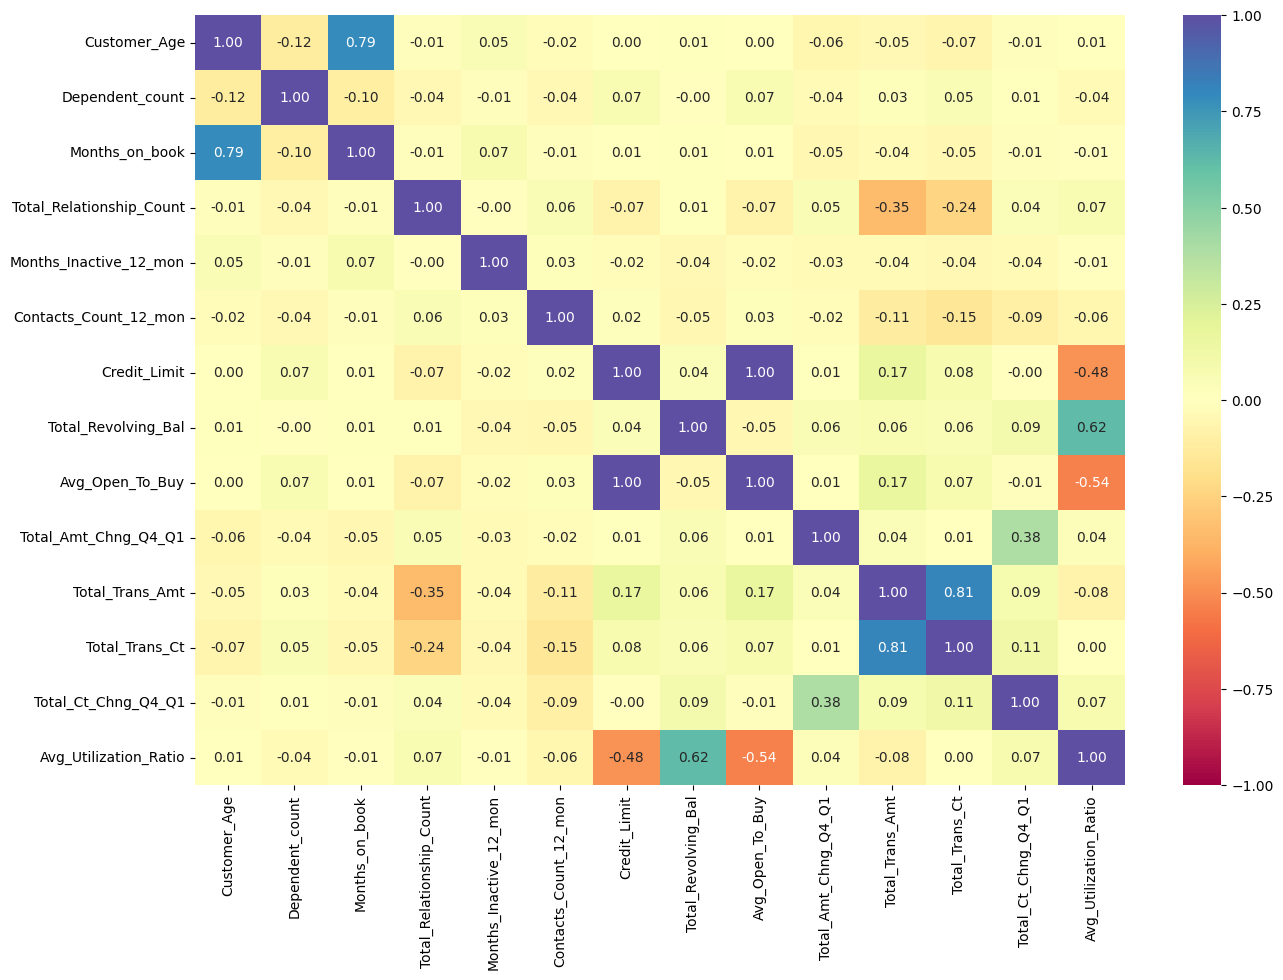

In [ ]:
plt.figure(figsize=(15,10))
sns.heatmap(num_data.corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()


As seen above we have many strong positive and negative correlations between the neumerical variables.

- We see strong posititve corelations between
  - Total Revolving Balance and Avg. Utilization Ration (.62)
  - Total Transaction Ammount and Total Transaction Count (.81)
  - Credit Limit and Avg. Open to Buy (1)
  - Months on book and Customer Age (.79)
- The Negative Correlations are:
  - Credit Limit and Avg Utilization Ration (-.48)
  - Avg Open to Buy and Avg Utilization Ratio (-.54)

The positive corellations make sense as if one of those variables increase it results in an increase in the appropriate variable. While for the negative correlation it is logical as if Avg Utilization rate decreases it means that either your credit limit went up or you are not using your credit to your full credit limit.

In [ ]:
sns.pairplot(num_data,diag_kind="kde")
plt.show()

Output hidden; open in https://colab.research.google.com to view.

Useing the pairplot we can see the skewness and distributions of all the numeric variables and determine if binning is necessary.

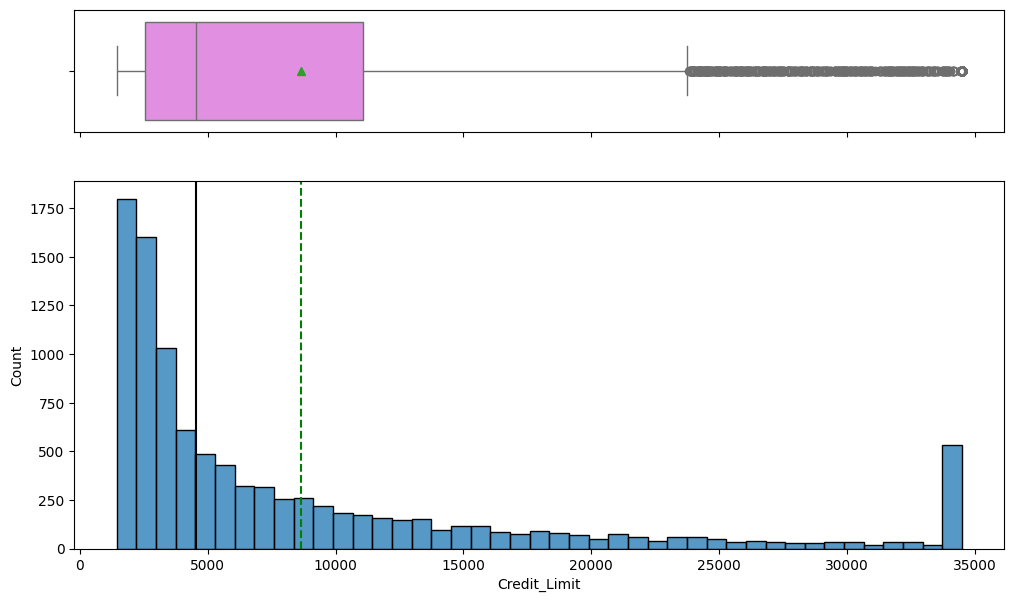

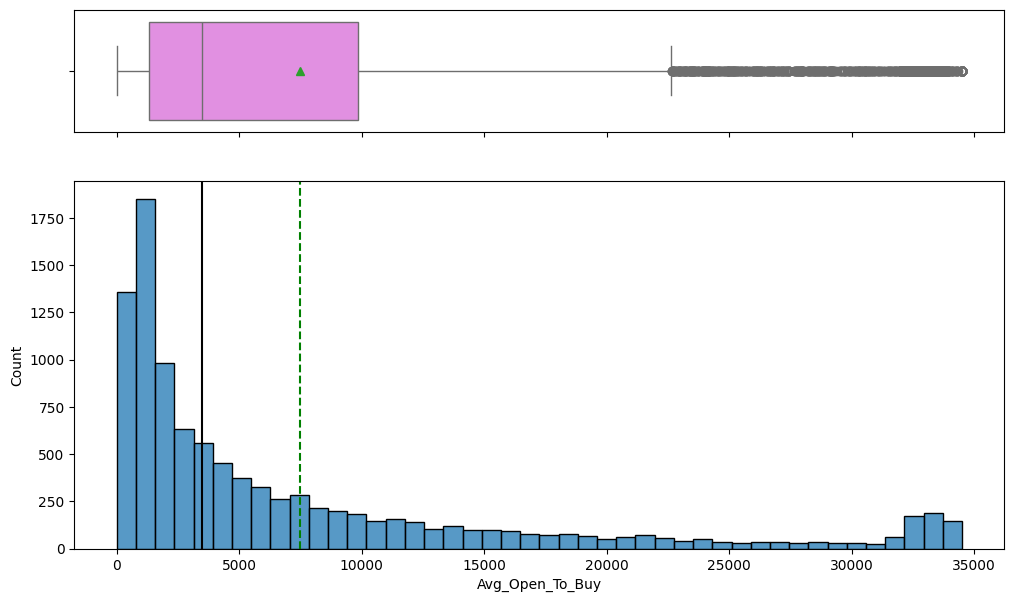

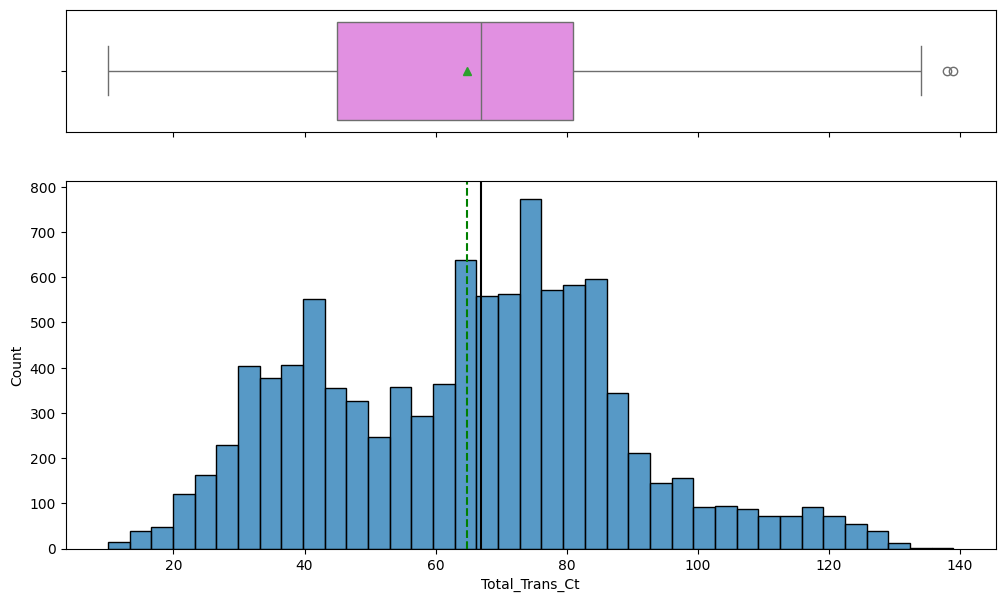

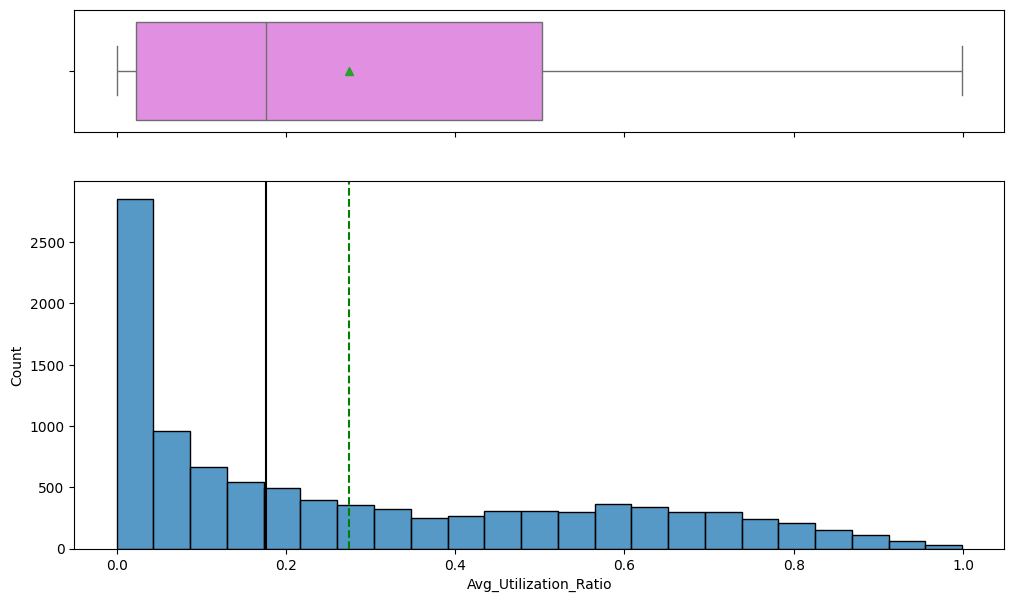

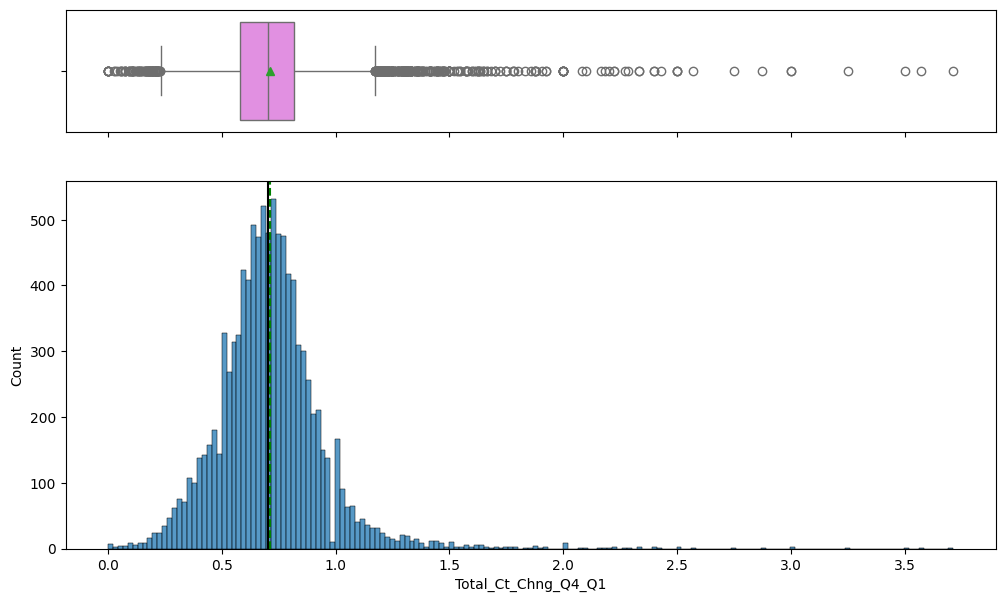

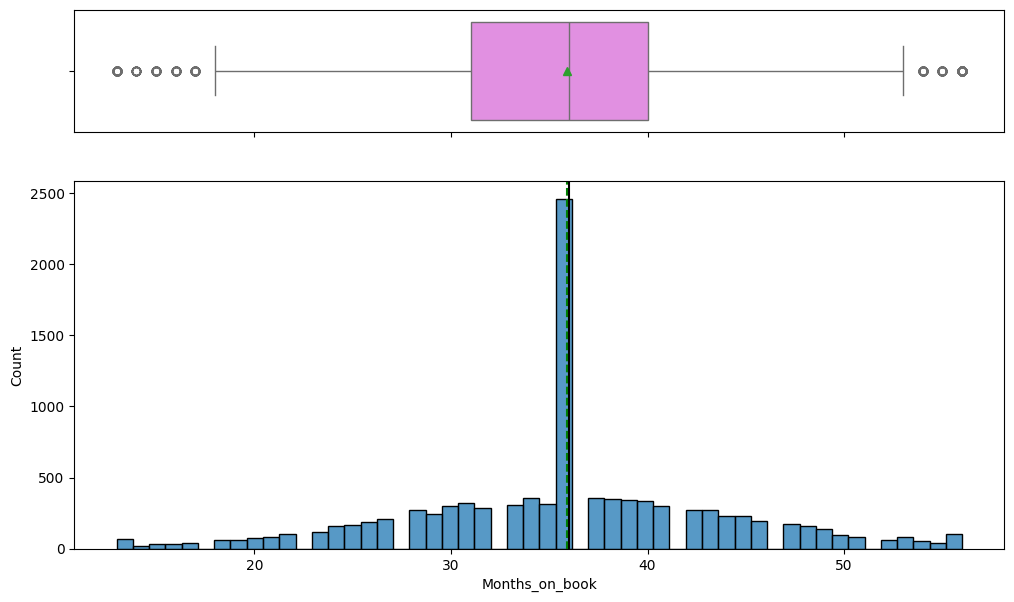

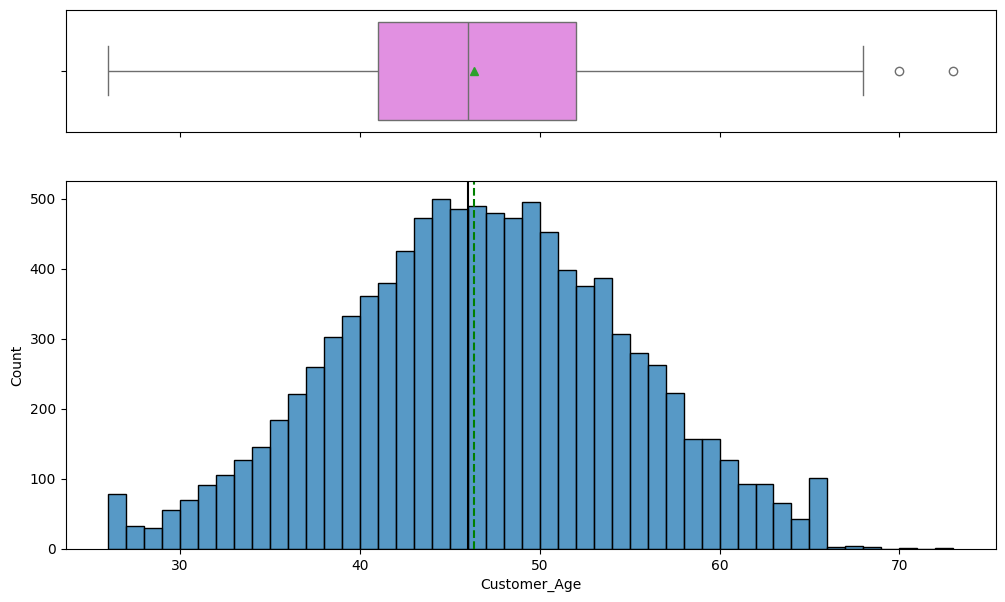

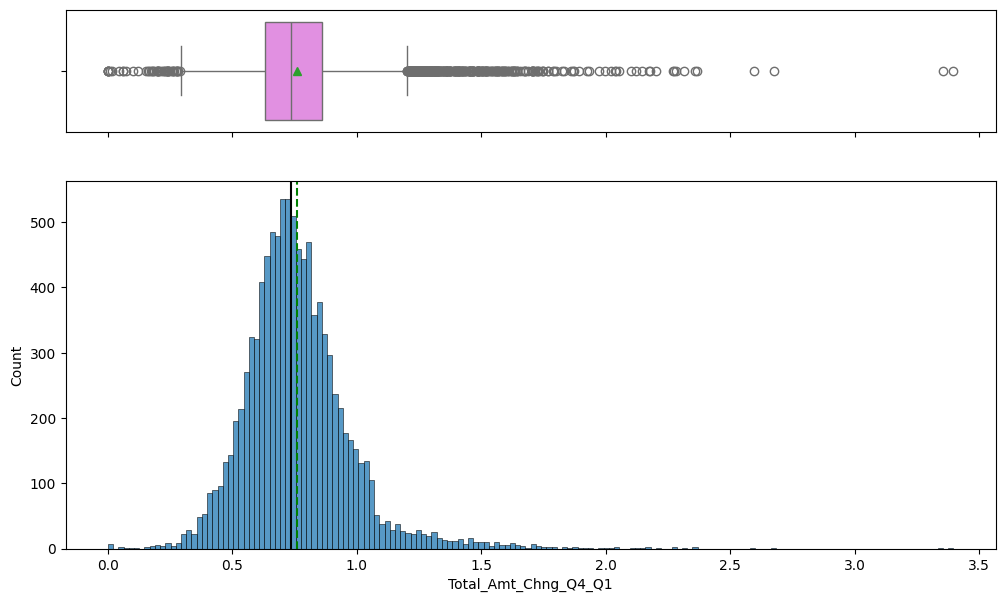

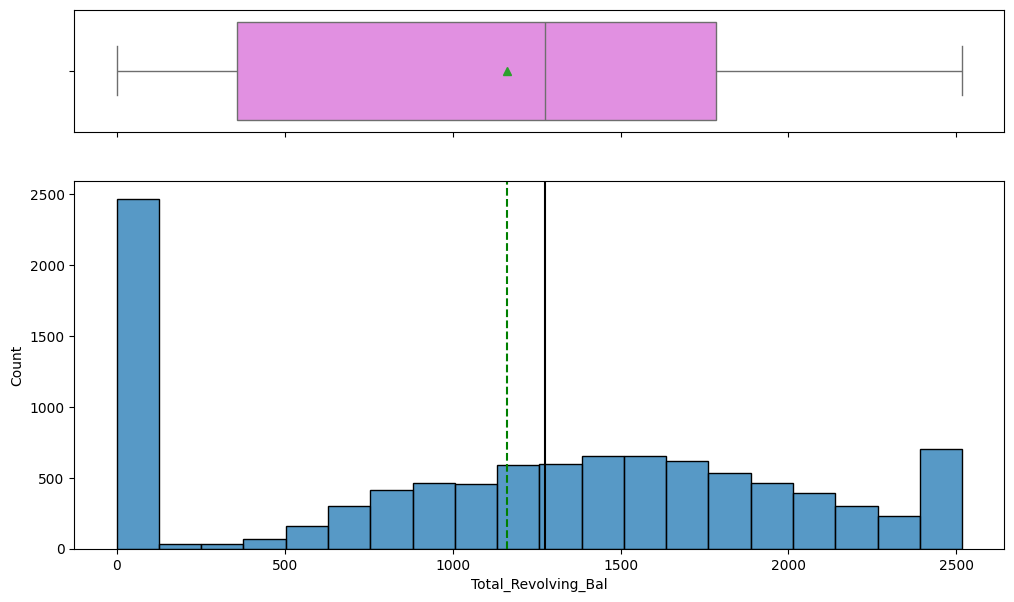

In [ ]:
histogram_boxplot(data, "Credit_Limit")
histogram_boxplot(data, "Avg_Open_To_Buy")
histogram_boxplot(data, "Total_Trans_Ct")
histogram_boxplot(data, "Avg_Utilization_Ratio")
histogram_boxplot(data, "Total_Ct_Chng_Q4_Q1")
histogram_boxplot(data, "Months_on_book")
histogram_boxplot(data, "Customer_Age")
histogram_boxplot(data, "Total_Amt_Chng_Q4_Q1")
histogram_boxplot(data, "Total_Revolving_Bal")

Using this histoplot function to check further distributions for binning purposes. Due to rightr skew. We find that Credit Limit, Avg Open to Buy, Avg Utilization Ratio, Total Ct Chng Q4 Q1, and Total Amt Chng Q4 Q1. All of these variables have a right skew resulting in a need for binning to make the model run more efficiently. Total Revolving Bal may need binning due to the abnormal distribution on the histogram, may need to bin this variable.

## Data Pre-processing

###Feature Engingeering

In [ ]:
data.nunique()

,0
Attrition_Flag,2
Customer_Age,45
Gender,2
Dependent_count,6
Education_Level,6
Marital_Status,3
Income_Category,6
Card_Category,4
Months_on_book,44
Total_Relationship_Count,6


In [ ]:
# Binning the Credit_Limit Variable
data['Credit_Limit'] = pd.cut(data['Credit_Limit'], bins=[1000, 5000, 10000, 15000, 20000, 25000, 30000, 35000], labels=['1k-5k', '5k-10k', '10k-15k', '15k-20k', '20k-25k', '25k-30k', '30k+'])
data.head()


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,10k-15k,777,11914.000,1.335,1144,42,1.625,0.061
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,5k-10k,864,7392.000,1.541,1291,33,3.714,0.105
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,1k-5k,0,3418.000,2.594,1887,20,2.333,0.000
3,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,1k-5k,2517,796.000,1.405,1171,20,2.333,0.760
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,1k-5k,0,4716.000,2.175,816,28,2.500,0.000


In [ ]:
data['Avg_Open_To_Buy'] = bc['Avg_Open_To_Buy']

In [ ]:
# Binning the Avg_Utilization_Ratio Variable
data['Avg_Utilization_Ratio'] = pd.qcut(data['Avg_Utilization_Ratio'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])


In [ ]:
data.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,10k-15k,777,11914.000,1.335,1144,42,1.625,Q2
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,5k-10k,864,7392.000,1.541,1291,33,3.714,Q2
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,1k-5k,0,3418.000,2.594,1887,20,2.333,Q1
3,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,1k-5k,2517,796.000,1.405,1171,20,2.333,Q4
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,1k-5k,0,4716.000,2.175,816,28,2.500,Q1


In [ ]:
data['Avg_Open_To_Buy'] = bc['Avg_Open_To_Buy']

#Split into quartiles so that the outliers and everything is easier to handle and easier to trace.
data['Avg_Open_To_Buy'] = pd.qcut(data['Avg_Open_To_Buy'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
data.head()


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,10k-15k,777,Q4,1.335,1144,42,1.625,Q2
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,5k-10k,864,Q3,1.541,1291,33,3.714,Q2
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,1k-5k,0,Q2,2.594,1887,20,2.333,Q1
3,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,1k-5k,2517,Q1,1.405,1171,20,2.333,Q4
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,1k-5k,0,Q3,2.175,816,28,2.500,Q1


In [ ]:
data['Total_Ct_Chng_Q4_Q1'] = bc['Total_Ct_Chng_Q4_Q1']
data['Total_Amt_Chng_Q4_Q1'] = bc['Total_Amt_Chng_Q4_Q1']

# Bin the total_Ct_Chng_Q4_Q1 column
data['Total_Ct_Chng_Q4_Q1'] = pd.cut(data['Total_Ct_Chng_Q4_Q1'], bins = [0,1,1.01,4], labels=['< 1', '= 1', '> 1'])

# Bin the Total_Amt_Chng_Q4_Q1 column
data['Total_Amt_Chng_Q4_Q1'] = pd.cut(data['Total_Amt_Chng_Q4_Q1'], bins = [0,1,1.01,4], labels=['< 1', '= 1', '> 1'])



In [ ]:
#Sanity Check
data1 = data.copy()
data1.head()


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,10k-15k,777,Q4,> 1,1144,42,> 1,Q2
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,5k-10k,864,Q3,> 1,1291,33,> 1,Q2
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,1k-5k,0,Q2,> 1,1887,20,> 1,Q1
3,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,1k-5k,2517,Q1,> 1,1171,20,> 1,Q4
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,1k-5k,0,Q3,> 1,816,28,> 1,Q1


In [ ]:
# find all the unique values of all non numerical variables

# Iterate through columns and print unique values for non-numerical columns
for column in data1.columns:
    if data1[column].dtype == 'object':
        unique_values = data1[column].unique()
        print(f"Unique values for {column}: {unique_values}")


Unique values for Attrition_Flag: ['Existing Customer' 'Attrited Customer']
Unique values for Gender: ['M' 'F']
Unique values for Education_Level: ['High School' 'Graduate' 'Uneducated' nan 'College' 'Post-Graduate'
 'Doctorate']
Unique values for Marital_Status: ['Married' 'Single' nan 'Divorced']
Unique values for Income_Category: ['$60K - $80K' 'Less than $40K' '$80K - $120K' '$40K - $60K' '$120K +'
 'abc']
Unique values for Card_Category: ['Blue' 'Gold' 'Silver' 'Platinum']


In [ ]:
data1.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,10k-15k,777,Q4,> 1,1144,42,> 1,Q2
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,5k-10k,864,Q3,> 1,1291,33,> 1,Q2
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,1k-5k,0,Q2,> 1,1887,20,> 1,Q1
3,Existing Customer,40,F,4,High School,NaN,Less than $40K,Blue,34,3,4,1,1k-5k,2517,Q1,> 1,1171,20,> 1,Q4
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,1k-5k,0,Q3,> 1,816,28,> 1,Q1


In [ ]:
# we need to pass numerical values for each categorical column for imputation so we will label encode them
gender = {"M": 0, "F": 1}
data1["Gender"] = data1["Gender"].map(gender)

education_level = {
    "Graduate": 0,
    "Uneducated": 1,
    "High School": 2,
    "College": 3,
    "Post-Graduate": 4,
    "Doctorate": 5
}
data1["Education_Level"] = data1["Education_Level"].map(education_level)

attrition_flag = {"Existing Customer": 0, "Attrited Customer": 1}
data1["Attrition_Flag"] = data1["Attrition_Flag"].map(attrition_flag)

marital_status = {"Married": 0, "Single": 1, "Divorced": 2}
data1["Marital_Status"] = data1["Marital_Status"].map(marital_status)

income_category = {
    "Less than $40K": 0,
    "$40K - $60K": 1,
    "$60K - $80K": 2,
    "$80K - $120K": 3,
    "$120K +": 4,
    "abc": None
}
data1["Income_Category"] = data1["Income_Category"].map(income_category)

card_Category = {"Blue": 0, "Silver": 1, "Gold": 2, "Platinum": 3}
data1["Card_Category"] = data1["Card_Category"].map(card_Category)



In [ ]:
data1.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,0,45,0,3,2.000,0.000,2.000,0,39,5,1,3,10k-15k,777,Q4,> 1,1144,42,> 1,Q2
1,0,49,1,5,0.000,1.000,0.000,0,44,6,1,2,5k-10k,864,Q3,> 1,1291,33,> 1,Q2
2,0,51,0,3,0.000,0.000,3.000,0,36,4,1,0,1k-5k,0,Q2,> 1,1887,20,> 1,Q1
3,0,40,1,4,2.000,NaN,0.000,0,34,3,4,1,1k-5k,2517,Q1,> 1,1171,20,> 1,Q4
4,0,40,0,3,1.000,0.000,2.000,0,21,5,1,0,1k-5k,0,Q3,> 1,816,28,> 1,Q1


- Values have been encoded.
- We will do missing value imputation after splitting the data into train, test and validation to avoid data leakage

##Data Preparation for Modeling

In [ ]:
X = data1.drop(["Attrition_Flag"], axis=1)
y = data1["Attrition_Flag"]

In [ ]:
# Splitting data into training, validation and test set:
# first we split data into 2 parts, say temporary and test

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

# then we split the temporary set into train and validation

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp
)
print(X_train.shape, X_val.shape, X_test.shape)

(6075, 19) (2026, 19) (2026, 19)


In [ ]:
print("Number of rows in train data =", X_train.shape[0])
print("Number of rows in validation data =", X_val.shape[0])
print("Number of rows in test data =", X_test.shape[0])

Number of rows in train data = 6075
Number of rows in validation data = 2026
Number of rows in test data = 2026


## Missing value imputation




In [ ]:
data1.isnull().sum()
# and Abc in income category.

,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,1519
Marital_Status,749
Income_Category,1112
Card_Category,0
Months_on_book,0
Total_Relationship_Count,0


In [ ]:
data1['Total_Ct_Chng_Q4_Q1'].unique()

['> 1', '< 1', NaN]
Categories (3, object): ['< 1' < '= 1' < '> 1']

In [ ]:
# prompt: What data types do I have in data1

data1.dtypes


,0
Attrition_Flag,int64
Customer_Age,int64
Gender,int64
Dependent_count,int64
Education_Level,float64
Marital_Status,float64
Income_Category,float64
Card_Category,int64
Months_on_book,int64
Total_Relationship_Count,int64


In [ ]:
# Identify categorical and numerical columns
numerical_cols = X_train.select_dtypes(exclude=['category',]).columns.tolist()

# Impute numerical columns
num_imputer = SimpleImputer(strategy='mean')
X_train[numerical_cols] = num_imputer.fit_transform(X_train[numerical_cols])
X_val[numerical_cols] = num_imputer.transform(X_val[numerical_cols])
X_test[numerical_cols] = num_imputer.transform(X_test[numerical_cols])

# Impute Total Ct and Total Amt chng Q4 Q1
cat_imputer = SimpleImputer(strategy='constant', fill_value='one')
X_train[['Total_Ct_Chng_Q4_Q1', 'Total_Amt_Chng_Q4_Q1']] = cat_imputer.fit_transform(X_train[['Total_Ct_Chng_Q4_Q1', 'Total_Amt_Chng_Q4_Q1']])
X_val[['Total_Ct_Chng_Q4_Q1', 'Total_Amt_Chng_Q4_Q1']] = cat_imputer.transform(X_val[['Total_Ct_Chng_Q4_Q1', 'Total_Amt_Chng_Q4_Q1']])
X_test[['Total_Ct_Chng_Q4_Q1', 'Total_Amt_Chng_Q4_Q1']] = cat_imputer.transform(X_test[['Total_Ct_Chng_Q4_Q1', 'Total_Amt_Chng_Q4_Q1']])

#Check shows Customer Age has some missing values, accept data loss for the sake of time and use mean to correct.
age_imputer = SimpleImputer(strategy='mean')
X_train['Customer_Age'] = age_imputer.fit_transform(X_train[['Customer_Age']])
X_val['Customer_Age'] = age_imputer.transform(X_val[['Customer_Age']])
X_test['Customer_Age'] = age_imputer.transform(X_test[['Customer_Age']])



In [ ]:
# Checking that no column has missing values in train, validation or test sets
print(X_train.isna().sum())
print("-" * 30)
print(X_val.isna().sum())
print("-" * 30)
print(X_test.isna().sum())

Customer_Age                0
Gender                      0
Dependent_count             0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Credit_Limit                0
Total_Revolving_Bal         0
Avg_Open_To_Buy             0
Total_Amt_Chng_Q4_Q1        0
Total_Trans_Amt             0
Total_Trans_Ct              0
Total_Ct_Chng_Q4_Q1         0
Avg_Utilization_Ratio       0
dtype: int64
------------------------------
Customer_Age                0
Gender                      0
Dependent_count             0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Credit_Limit                0
Total_Revolving_Bal       

### Reverse Mapping for Encoded Variables

In [ ]:
## Function to inverse the encoding
def inverse_mapping(x, y):
    inv_dict = {v: k for k, v in x.items()}
    X_train[y] = X_train[y].map(inv_dict).astype("category")
    X_val[y] = X_val[y].map(inv_dict).astype("category")
    X_test[y] = X_test[y].map(inv_dict).astype("category")


In [ ]:
inverse_mapping(gender, "Gender")
inverse_mapping(education_level, "Education_Level")
inverse_mapping(marital_status, "Marital_Status")
inverse_mapping(income_category, "Income_Category")
inverse_mapping(card_Category, "Card_Category")


- Checking inverse mapped values/categories.

**Train Data Set**

In [ ]:
cols = X_train.select_dtypes(include=["object", "category", "float64"])
for i in cols.columns:
    print(X_train[i].value_counts())
    print("*" * 30)

Customer_Age
46.000    314
43.000    292
49.000    288
45.000    285
48.000    284
44.000    283
50.000    279
47.000    279
42.000    255
53.000    238
51.000    237
52.000    228
41.000    220
40.000    217
39.000    200
54.000    199
55.000    176
38.000    176
56.000    156
37.000    139
36.000    139
57.000    129
35.000    116
59.000     94
34.000     93
58.000     90
33.000     79
60.000     69
65.000     63
32.000     63
62.000     58
31.000     53
61.000     49
26.000     47
30.000     42
63.000     41
29.000     34
27.000     24
64.000     24
28.000     17
68.000      2
67.000      2
73.000      1
66.000      1
Name: count, dtype: int64
******************************
Gender
F    3193
M    2882
Name: count, dtype: int64
******************************
Dependent_count
2.000    1615
3.000    1605
1.000    1103
4.000     947
0.000     547
5.000     258
Name: count, dtype: int64
******************************
Education_Level
Graduate         1854
High School      1228
Uneducated   

**Validation Data Set**

In [ ]:
cols = X_val.select_dtypes(include=["object", "category","float64"])
for i in cols.columns:
    print(X_val[i].value_counts())
    print("*" * 30)

Customer_Age
44.000    112
45.000    110
49.000    100
42.000     95
46.000     94
43.000     93
47.000     91
48.000     90
53.000     87
50.000     83
40.000     79
52.000     75
41.000     74
51.000     71
39.000     64
37.000     57
38.000     56
55.000     52
57.000     50
56.000     49
54.000     47
36.000     42
35.000     42
58.000     36
59.000     28
60.000     28
33.000     27
34.000     27
31.000     22
32.000     20
61.000     18
65.000     17
26.000     16
62.000     16
63.000     15
64.000     11
29.000     10
30.000     10
27.000      6
28.000      4
67.000      1
70.000      1
Name: count, dtype: int64
******************************
Gender
F    1095
M     931
Name: count, dtype: int64
******************************
Dependent_count
3.000    572
2.000    520
1.000    364
4.000    315
0.000    169
5.000     86
Name: count, dtype: int64
******************************
Education_Level
Graduate         623
High School      404
Uneducated       306
College          199
Post-Gr

**Test Data Set**

In [ ]:
cols = X_test.select_dtypes(include=["object", "category","float64"])
for i in cols.columns:
    print(X_test[i].value_counts())
    print("*" * 30)

Customer_Age
47.000    109
49.000    107
44.000    105
48.000     98
45.000     91
51.000     90
50.000     90
43.000     88
41.000     85
46.000     82
42.000     76
52.000     73
38.000     71
39.000     69
40.000     65
37.000     64
53.000     62
54.000     61
56.000     57
55.000     51
57.000     44
36.000     40
59.000     35
58.000     31
60.000     30
34.000     26
35.000     26
61.000     26
32.000     23
65.000     21
33.000     21
62.000     19
30.000     18
31.000     16
26.000     15
29.000     12
63.000      9
64.000      8
28.000      8
27.000      2
66.000      1
67.000      1
Name: count, dtype: int64
******************************
Gender
F    1070
M     956
Name: count, dtype: int64
******************************
Dependent_count
3.000    555
2.000    520
1.000    371
4.000    312
0.000    188
5.000     80
Name: count, dtype: int64
******************************
Education_Level
Graduate         651
High School      381
Uneducated       300
College          196
Post-Gr

- Inverse mapping returned original labels.

In [ ]:
# Creating Dummy Variables/One-hot encoding

X_train = pd.get_dummies(X_train, drop_first=True)
X_val = pd.get_dummies(X_val, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)
print(X_train.shape, X_val.shape, X_test.shape)

(6075, 41) (2026, 40) (2026, 40)


Since the train data set has an extra column, I identified it via the error in the model building portion. Now I will drop Total_Amt_Chng_Q4_Q1_one to set it right.

In [ ]:
X_train = X_train.drop(["Total_Amt_Chng_Q4_Q1_one"], axis=1)
print(X_train.shape, X_val.shape, X_test.shape)

(6075, 40) (2026, 40) (2026, 40)


## Model Building

### Model evaluation criterion

The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model.
- False negatives (FN) are real failures in a generator where there is no detection by model.
- False positives (FP) are failure detections in a generator where there is no failure.

**Which metric to optimize?**

* We need to choose the metric which will ensure that the maximum number of generator failures are predicted correctly by the model.
* We would want Recall to be maximized as greater the Recall, the higher the chances of minimizing false negatives.
* We want to minimize false negatives because if a model predicts that a machine will have no failure when there will be a failure, it will increase the maintenance cost.

**Let's define a function to output different metrics (including recall) on the train and test set and a function to show confusion matrix so that we do not have to use the same code repetitively while evaluating models.**

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1": f1

        },
        index=[0],
    )

    return df_perf

### Model Building with original data

Sample code for model building with original data

In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))


print("\n" "Training Performance:" "\n")
for name, model in models:
    model.fit(X_train, y_train)
    scores = recall_score(y_train, model.predict(X_train))
    print("{}: {}".format(name, scores))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train, y_train)
    scores_val = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores_val))


Training Performance:

Bagging: 0.9733606557377049
Random forest: 1.0
GBM: 0.8422131147540983
Adaboost: 0.8125
dtree: 1.0

Validation Performance:

Bagging: 0.8006134969325154
Random forest: 0.7392638036809815
GBM: 0.8404907975460123
Adaboost: 0.8282208588957055
dtree: 0.7760736196319018


In [ ]:
print("\nTraining and Validation Performance Difference:\n")

for name, model in models:
    model.fit(X_train, y_train)
    scores_train = recall_score(y_train, model.predict(X_train))
    scores_val = recall_score(y_val, model.predict(X_val))
    difference1 = scores_train - scores_val
    print("{}: Training Score: {:.4f}, Validation Score: {:.4f}, Difference: {:.4f}".format(name, scores_train, scores_val, difference1))


Training and Validation Performance Difference:

Bagging: Training Score: 0.9734, Validation Score: 0.8006, Difference: 0.1727
Random forest: Training Score: 1.0000, Validation Score: 0.7393, Difference: 0.2607
GBM: Training Score: 0.8422, Validation Score: 0.8405, Difference: 0.0017
Adaboost: Training Score: 0.8125, Validation Score: 0.8282, Difference: -0.0157
dtree: Training Score: 1.0000, Validation Score: 0.7761, Difference: 0.2239


We can see that the best model was the Gradient boosting method with a plus 80% recall score meaning that it does a good job of limiting false negatives which is improtant in our context as a false negative means we misidentified a customer that would cancel their card for one that wouldn't. The next best model was Adaboost model. With the validation scoring better than the training data that means that we have generalized well.

### Model Building with Oversampled data


In [ ]:
print("Before Oversampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before Oversampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

sm = SMOTE(
    sampling_strategy=1, k_neighbors=5, random_state=1
)  # Synthetic Minority Over Sampling Technique
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)


print("After Oversampling, counts of label 'Yes': {}".format(sum(y_train_over == 1)))
print("After Oversampling, counts of label 'No': {} \n".format(sum(y_train_over == 0)))


print("After Oversampling, the shape of train_X: {}".format(X_train_over.shape))
print("After Oversampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before Oversampling, counts of label 'Yes': 976
Before Oversampling, counts of label 'No': 5099 

After Oversampling, counts of label 'Yes': 5099
After Oversampling, counts of label 'No': 5099 

After Oversampling, the shape of train_X: (10198, 40)
After Oversampling, the shape of train_y: (10198,) 



In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(base_estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1, class_weight='balanced')))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))

print("\n" "Training Performance:" "\n")
for name, model in models:
    model.fit(X_train_over, y_train_over)
    scores = recall_score(y_train_over, model.predict(X_train_over))
    print("{}: {}".format(name, scores))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train_over, y_train_over)
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Training Performance:

Bagging: 0.9974504804863699
Random forest: 1.0
GBM: 0.9760737399490096
Adaboost: 0.9623455579525397
dtree: 1.0

Validation Performance:

Bagging: 0.8098159509202454
Random forest: 0.7576687116564417
GBM: 0.8558282208588958
Adaboost: 0.8466257668711656
dtree: 0.7944785276073619


In [ ]:
print("\nTraining and Validation Performance Difference:\n")

for name, model in models:
    model.fit(X_train_over, y_train_over)
    scores_train = recall_score(y_train_over, model.predict(X_train_over))
    scores_val = recall_score(y_val, model.predict(X_val))
    difference2 = scores_train - scores_val
    print("{}: Training Score: {:.4f}, Validation Score: {:.4f}, Difference: {:.4f}".format(name, scores_train, scores_val, difference2))


Training and Validation Performance Difference:

Bagging: Training Score: 0.9975, Validation Score: 0.8098, Difference: 0.1876
Random forest: Training Score: 1.0000, Validation Score: 0.7577, Difference: 0.2423
GBM: Training Score: 0.9761, Validation Score: 0.8558, Difference: 0.1202
Adaboost: Training Score: 0.9623, Validation Score: 0.8466, Difference: 0.1157
dtree: Training Score: 1.0000, Validation Score: 0.7945, Difference: 0.2055


After running an oversampled train and validation data set we can see that it is less effective than the original data models. This is due to the fact that the model is trained to on synthetic data. It could have overfit on that data or even memorized the new sythetic data that might have repeated. This can hurt model performance. But in the oversampled data adaboosting method performed better than gradient boosting method.

### Model Building with Undersampled data

In [ ]:
# Random undersampler for under sampling the data
rus = RandomUnderSampler(random_state=1, sampling_strategy=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

In [ ]:
print("Before Under Sampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before Under Sampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

print("After Under Sampling, counts of label 'Yes': {}".format(sum(y_train_un == 1)))
print("After Under Sampling, counts of label 'No': {} \n".format(sum(y_train_un == 0)))

print("After Under Sampling, the shape of train_X: {}".format(X_train_un.shape))
print("After Under Sampling, the shape of train_y: {} \n".format(y_train_un.shape))

Before Under Sampling, counts of label 'Yes': 976
Before Under Sampling, counts of label 'No': 5099 

After Under Sampling, counts of label 'Yes': 976
After Under Sampling, counts of label 'No': 976 

After Under Sampling, the shape of train_X: (1952, 40)
After Under Sampling, the shape of train_y: (1952,) 



In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(base_estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1, class_weight='balanced')))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))


print("\n" "Training Performance:" "\n")
for name, model in models:
    model.fit(X_train_un, y_train_un)
    scores = recall_score(y_train_un, model.predict(X_train_un))
    print("{}: {}".format(name, scores))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train_un, y_train_un)
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Training Performance:

Bagging: 0.9887295081967213
Random forest: 1.0
GBM: 0.9651639344262295
Adaboost: 0.9395491803278688
dtree: 1.0

Validation Performance:

Bagging: 0.9202453987730062
Random forest: 0.8987730061349694
GBM: 0.941717791411043
Adaboost: 0.9539877300613497
dtree: 0.8926380368098159


In [ ]:
print("\nTraining and Validation Performance Difference:\n")

for name, model in models:
    model.fit(X_train_un, y_train_un)
    scores_train = recall_score(y_train_un, model.predict(X_train_un))
    scores_val = recall_score(y_val, model.predict(X_val))
    difference3 = scores_train - scores_val
    print("{}: Training Score: {:.4f}, Validation Score: {:.4f}, Difference: {:.4f}".format(name, scores_train, scores_val, difference3))


Training and Validation Performance Difference:

Bagging: Training Score: 0.9887, Validation Score: 0.9202, Difference: 0.0685
Random forest: Training Score: 1.0000, Validation Score: 0.8988, Difference: 0.1012
GBM: Training Score: 0.9652, Validation Score: 0.9417, Difference: 0.0234
Adaboost: Training Score: 0.9395, Validation Score: 0.9540, Difference: -0.0144
dtree: Training Score: 1.0000, Validation Score: 0.8926, Difference: 0.1074


As we can see with the undersampled data we see higher recall scores. We also see that adaboost scored better with unseen data. Meaning that the model can generalize well and properly predict customers that want to leave properly. We can also see that gradient boosting method is the second best in terms of recall scores.

### HyperparameterTuning

#### Sample Parameter Grids

**Note**

1. Sample parameter grids have been provided to do necessary hyperparameter tuning. These sample grids are expected to provide a balance between model performance improvement and execution time. One can extend/reduce the parameter grid based on execution time and system configuration.
  - Please note that if the parameter grid is extended to improve the model performance further, the execution time will increase


- For Gradient Boosting:

```
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "subsample":[0.7,0.9],
    "max_features":[0.5,0.7,1],
}
```

- For Adaboost:

```
param_grid = {
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "base_estimator": [
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ],
}
```

- For Bagging Classifier:

```
param_grid = {
    'max_samples': [0.8,0.9,1],
    'max_features': [0.7,0.8,0.9],
    'n_estimators' : [30,50,70],
}
```
- For Random Forest:

```
param_grid = {
    "n_estimators": [50,110,25],
    "min_samples_leaf": np.arange(1, 4),
    "max_features": [np.arange(0.3, 0.6, 0.1),'sqrt'],
    "max_samples": np.arange(0.4, 0.7, 0.1)
}
```

- For Decision Trees:

```
param_grid = {
    'max_depth': np.arange(2,6),
    'min_samples_leaf': [1, 4, 7],
    'max_leaf_nodes' : [10, 15],
    'min_impurity_decrease': [0.0001,0.001]
}
```

- For XGBoost (optional):

```
param_grid={'n_estimators':np.arange(50,110,25),
            'scale_pos_weight':[1,2,5],
            'learning_rate':[0.01,0.1,0.05],
            'gamma':[1,3],
            'subsample':[0.7,0.9]
}
```

#### Tuning the AdaBoost Classifier for Undersampled Data

I chose to tune this model due it being the highest performing model interms of recall score.

In [ ]:
# defining model
Model = AdaBoostClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "base_estimator": [
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ],
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_jobs = -1, n_iter=50, scoring=scorer, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_un, y_train_un)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'n_estimators': 100, 'learning_rate': 0.1, 'base_estimator': DecisionTreeClassifier(max_depth=2, random_state=1)} with CV score=0.9334275248560964:


In [ ]:
tuned_adb = AdaBoostClassifier(
    random_state=1,
    n_estimators=100,
    learning_rate=0.1,
    base_estimator=DecisionTreeClassifier(max_depth=2, random_state=1),
)
tuned_adb.fit(X_train_un, y_train_un)

AdaBoostClassifier(base_estimator=DecisionTreeClassifier(max_depth=2,
                                                         random_state=1),
                   learning_rate=0.1, n_estimators=100, random_state=1)

In [ ]:
# Checking model's performance on training set
adb_train = model_performance_classification_sklearn(tuned_adb, X_train_un, y_train_un)
adb_train

,Accuracy,Recall,Precision,F1
0,0.903,0.915,0.893,0.904


In [ ]:
# Checking model's performance on validation set
adb_val = model_performance_classification_sklearn(tuned_adb, X_val, y_val)
adb_val

,Accuracy,Recall,Precision,F1
0,0.886,0.905,0.596,0.719


#### Tuning method for Gradient Boosting with Undersampled Data

In [343]:
# defining model
Model = GradientBoostingClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "subsample":[0.7,0.9],
    "max_features":[0.5,0.7,1],
}
#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=10, n_jobs = -1, scoring=scorer, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over,y_train_over)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'subsample': 0.7, 'n_estimators': 100, 'max_features': 0.7, 'learning_rate': 0.05, 'init': DecisionTreeClassifier(random_state=1)} with CV score=0.9290167215070524:


In [344]:
tuned_gbm1 = GradientBoostingClassifier(
    random_state=1,
    subsample=0.7,
    n_estimators=100,
    max_features=0.7,
    learning_rate=0.05,
    init=AdaBoostClassifier(random_state=1),
)
tuned_gbm1.fit(X_train_un, y_train_un)

GradientBoostingClassifier(init=AdaBoostClassifier(random_state=1),
                           learning_rate=0.05, max_features=0.7, random_state=1,
                           subsample=0.7)

In [345]:
# Checking model's performance on training set
gbm1_train = model_performance_classification_sklearn(
    tuned_gbm1, X_train_un, y_train_un
)
gbm1_train

,Accuracy,Recall,Precision,F1
0,0.946,0.953,0.940,0.947


In [346]:
# Checking model's performance on validation set
gbm1_val = model_performance_classification_sklearn(tuned_gbm1, X_val, y_val)
gbm1_val

,Accuracy,Recall,Precision,F1
0,0.914,0.933,0.665,0.777


I selected this model as it had the second highest recall score without tuning. Now after tuning it is better than adaboosting on undersampled data.

#### Sample tuning method for Gradient Boost with Original data

In [348]:
# defining model
Model = GradientBoostingClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "subsample":[0.7,0.9],
    "max_features":[0.5,0.7,1],
}

# Type of scoring used to compare parameter combinations
#scorer = metrics.make_scorer(metrics.recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model, param_distributions=param_grid, n_iter=10, n_jobs = -1, scoring=scorer, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train,y_train)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))


Best parameters are {'subsample': 0.7, 'n_estimators': 100, 'max_features': 0.7, 'learning_rate': 0.05, 'init': DecisionTreeClassifier(random_state=1)} with CV score=0.761250654107797:


In [349]:
tuned_gbm2 = GradientBoostingClassifier(
    random_state=1,
    subsample=0.7,
    n_estimators=100,
    max_features=0.7,
    learning_rate=0.05,
    init=AdaBoostClassifier(random_state=1),
)
tuned_gbm2.fit(X_train, y_train)

GradientBoostingClassifier(init=AdaBoostClassifier(random_state=1),
                           learning_rate=0.05, max_features=0.7, random_state=1,
                           subsample=0.7)

In [350]:
# Checking model's performance on training set
gbm2_train = model_performance_classification_sklearn(
    tuned_gbm2, X_train, y_train
)
gbm2_train

,Accuracy,Recall,Precision,F1
0,0.950,0.751,0.926,0.829


In [352]:
# Checking model's performance on validation set
gbm2_val = model_performance_classification_sklearn(
    tuned_gbm2, X_val, y_val
)
gbm2_val

,Accuracy,Recall,Precision,F1
0,0.950,0.770,0.906,0.833


This was the third best model, in terms of difference between the train vs. validation. I choose this to see if I could increase the recall score by using hyper parameter training.

## Model Comparison and Final Model Selection

In [353]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        gbm1_train.T,
        gbm2_train.T,
        adb_train.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Gradient boosting trained with Undersampled data",
    "Gradient boosting trained with Oversampled data",
    "AdaBoost trained with Undersampled data",
]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Gradient boosting trained with Undersampled data,Gradient boosting trained with Oversampled data,AdaBoost trained with Undersampled data
Accuracy,0.946,0.950,0.903
Recall,0.953,0.751,0.915
Precision,0.940,0.926,0.893
F1,0.947,0.829,0.904


In [354]:
# Validation performance comparison

models_train_comp_df = pd.concat(
    [ gbm1_val.T, gbm2_val.T, adb_val.T], axis=1,
)
models_train_comp_df.columns = [
    "Gradient boosting trained with Undersampled data",
    "Gradient boosting trained with Oversampled data",
    "AdaBoost trained with Undersampled data",
]
print("Validation performance comparison:")
models_train_comp_df

Validation performance comparison:


,Gradient boosting trained with Undersampled data,Gradient boosting trained with Oversampled data,AdaBoost trained with Undersampled data
Accuracy,0.914,0.950,0.886
Recall,0.933,0.770,0.905
Precision,0.665,0.906,0.596
F1,0.777,0.833,0.719


- The Gradient boosting model with undersampled data has the best recall score meaning that it has the best generalization. Thus we claim that this is the best model.

#### Test Set Final Performance

In [355]:
# Let's check the performance on test set
gb_test = model_performance_classification_sklearn(tuned_gbm1, X_test, y_test)
gb_test

,Accuracy,Recall,Precision,F1
0,0.926,0.966,0.693,0.807


This gradient boosted model got a ~96% recall score which is in line with the train and validation sets. Thus we can confirm that this is the best model.

**Feature Importance**

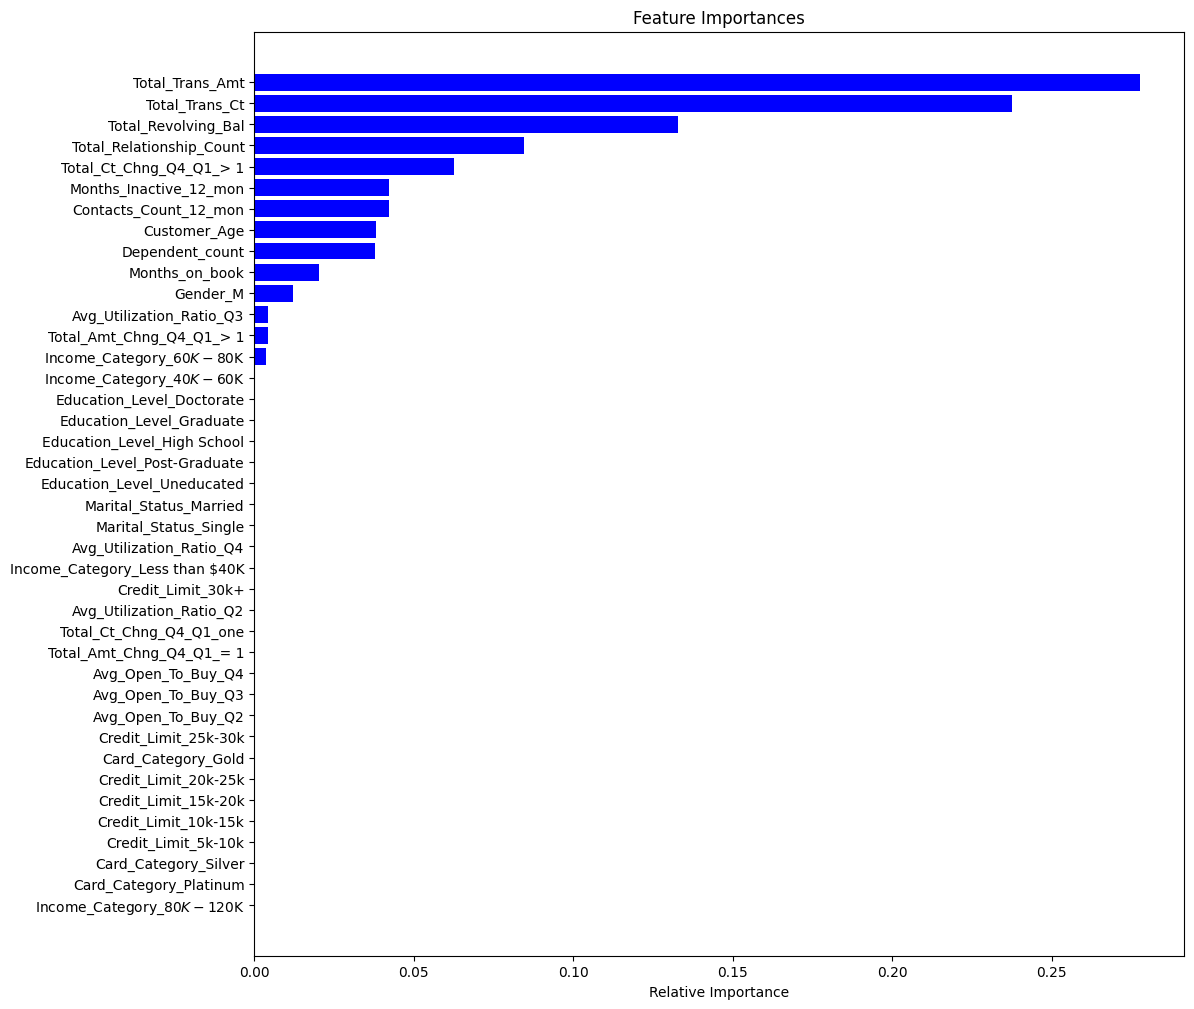

In [356]:
feature_names = X_train.columns
importances = tuned_adb.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="blue", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

As we can see the most important features for our selected model is Total Transanction Ammount, Total Transaction count, and Total revolving balance.

# Business Insights and Conclusions

***
- From this we can infer that if a customer has a transaction ammount around $2000 dollars they are more likely to be attrited.
- We can if customers are closer to 40 transactions then they are more prone to be an Attrited account.
- The bank can entice customers to spend more or have more transactions by sending out ammount or count oriented rewards that could build customer loyalty.
- We can also see that status of the card doesn't have an impact on cutomer loyalty and retention.
- Ultimately, the best way to keep customers is to keep them engaged and reward them for using your credit card. If you want to find "at risk" customers that may leave identify customers that have slowing transactions and lower spends on their cards.